In [2]:
import numpy as np
from astroquery.vizier import Vizier
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord


In [3]:
#Datensätze Laden

v = Vizier(columns=["**"], row_limit=-1)     # v ist Anfrage Objekt mit row limit -1 damit nicht nur die standard ersten 50 einträge geladen werden sondern alle
v.VIZIER_SERVER = "vizier.cfa.harvard.edu"   # Server ändern das Strassbourg gehackt wurde
bosch2016 = v.get_catalogs("J/ApJ/831/134")[0]
print(bosch2016.colnames)
#Weitere interessante Cataloge
#J/ApJ/798/54  Graham 2015
#J/ApJ/811/91  Woo 2015
#J/ApJ/897/111 Zaw 2020

['recno', 'Name', 'f_Name', 'Dist', 'e_Dist', 'logBHMass', 'E_logBHMass', 'e_logBHMass', 'logsigma', 'e_logsigma', 'logLk', 'e_logLk', 'logRe', 'e_logRe', 'cov', 'C28', 'e_C28', 'logAGN', 'e_logAGN', 'Meth', 'Refs', 'SimbadName', 'NED', '_RA', '_DE']


In [5]:
#Benötigt Daten bereinigen

raw_mbh_bosch = np.array(bosch2016["logBHMass"], dtype=float)
raw_sigma_bosch = np.array(bosch2016["logsigma"], dtype=float)

mask= (~np.isnan(raw_mbh_bosch)) & (~np.isnan(raw_sigma_bosch)) & (raw_sigma_bosch > 0)  #Maske um Leere und Negative Werte zu filtern

sigma_bosch = raw_sigma_bosch[mask]   #von leeren und unrealistischen einträgen befreite Daten
mbh_bosch = raw_mbh_bosch[mask]
print(len(mbh_bosch))

245


In [ ]:
#Bootstrapping

def bootstrapping_mean(data, anzahl=5000):                           #data = die Daten die gebootstrapt werden sollen  n_boot = anzahl der simulierten neuverteilungen
  rng = np.random.default_rng(42069)                                 #rng mit festem Seed damit Resultat beim wiederaufruf des Notebooks gleichbleibt
  sims = np.empty(anzahl)                                            #leeres array in dem die simulierten Daten nach jedem durchlauf eingetragen werden 
  n = len(data)                                                      #Menge der Daten damit bei jeder simulation wieder identisch viele neu gezogen werden
  for i in range(anzahl):                                            #schleife die das gesamte sims array füllt 
    sample = rng.choice(data, size=n, replace=True)                  #neu generiertes sample aus der ziehung mit zurücklegen der ursprungs daten
    sims[i] = np.mean(sample)                                        #trägt für jedes generierte sample den median in das sims array ein
  konfidenz_low, konfidenz_high = np.percentile(sims, [2.5, 97.5])   #berechnet die grenzen für 95% Konfidenzintervall
  return np.mean(data),np.mean(sims), konfidenz_low, konfidenz_high, sims


Mittelwert OG log(M_BH): 7.62
Mittelwert Bootstrapping: 7.62      (Identisch da Erwartungstreu)
95%-Konfidenzintervall: [7.42, 7.82]


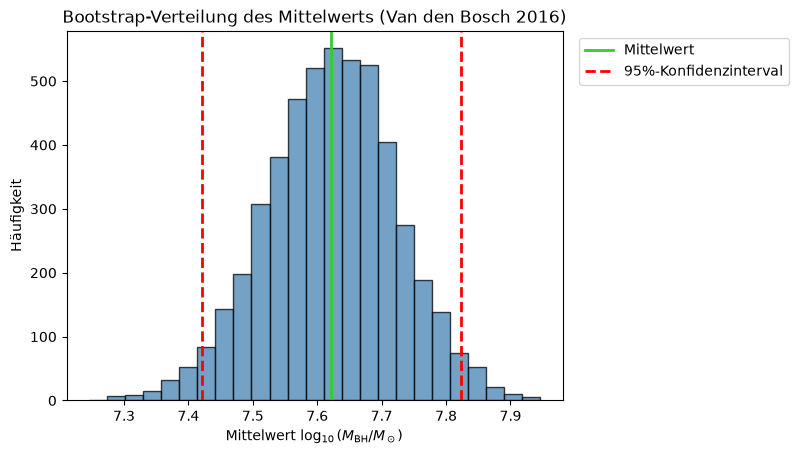

In [132]:
mean_og, mean_sim, low_konf, high_konf, mbh_sims = bootstrapping_mean(mbh_bosch)
print(f"Mittelwert OG log(M_BH): {mean_og:.2f}\nMittelwert Bootstrapping: {mean_sim:.2f}      (Identisch da Erwartungstreu)\n95%-Konfidenzintervall: [{low_m:.2f}, {high_m:.2f}]") #:.2f lässt nur 2 kommastellen ausgeben


plt.hist(mbh_sims, bins=25, color="steelblue", edgecolor="black", alpha=0.75)
plt.axvline(mean_sim, color="limegreen", linewidth=2, label="Mittelwert")
plt.axvline(low_konf, color="red", linestyle="--", linewidth=2)
plt.axvline(high_konf, color="red", linestyle="--", linewidth=2, label="95%-Konfidenzinterval")

plt.xlabel(r"Mittelwert $\log_{10}(M_{\mathrm{BH}} / M_\odot)$")
plt.ylabel("Häufigkeit")
plt.title("Bootstrap-Verteilung des Mittelwerts (Van den Bosch 2016)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

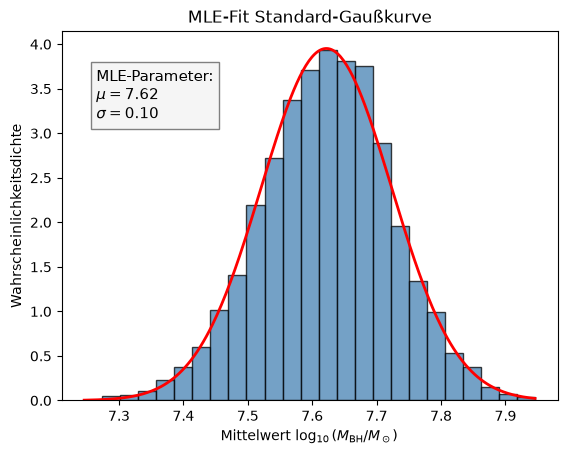

In [ ]:
mü = np.mean(mbh_sims)          #numpys mean und std/standarddeviation sind in dem Fall identisch mit dem MLE Schätzer
sigma = np.std(mbh_sims)

x = np.linspace(mbh_sims.min(), mbh_sims.max(), 300) #"kontinuirliche" basis für die Gauß-Kurve
gauss = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mü) / sigma) ** 2) #Standard Fromel für Gauß-Kurve


plt.hist(mbh_sims, bins=25, color="steelblue", edgecolor="black", alpha=0.75, density=True)   #density=True normiert die Verteilung auf Fläche 1 (damit Gaußkurve darüber passt)
plt.plot(x, gauss, color="red", linewidth=2)
plt.xlabel(r"Mittelwert $\log_{10}(M_{\mathrm{BH}}/M_\odot)$")
plt.ylabel("Wahrscheinlichkeitsdichte")
plt.title("MLE-Fit Standard-Gaußkurve")

text = f"MLE-Parameter:\n$\\mu = {mü:.2f}$\n$\\sigma = {sigma:.2f}$"
plt.text(0.07, 0.9, text, transform=plt.gca().transAxes, fontsize=11, verticalalignment="top", bbox=dict(facecolor="whitesmoke", edgecolor="gray"))

plt.show()

Tafel Zusammenfassung:

-Wir haben nur einen begrenzten Datensatz von 245 Einträgen und keine Grund-Population aus der man einfach weitere Samples beziehen könnte  
-Beim Bootstrapping nutzt man den konkreten Datensatz einfach hilfsweise als Grund-Population  
-Man zieht aus ihm einfach mehrere tausend neue Samples der gleichen größe  
-Dabei gilt das ziehen mit zurücklegen damit auch wirklich zu einem grad unterschiedliche neue Samples entstehen  
-sprich es werden einige daten punkte doppelt genommen andere garnicht je nach sample  

-Trägt man nun die Mittelwerte alle dieser Samples (bei uns 5000) als Histogramm auf erhält man den Graph  
-Mann kann einfach den Mittelwert und Konfidenzintervalle dieser Verteilung bestimmen   
-Konfidenzintervalle bei Bootstrapping:   
-man ORDNET die Sample Mittelwerte der GRÖßE nach und lässt entsprechenden Prozentsätze an den Ränder aus  
-Bei uns 95% Konfidenz man lässt die ersten und letzten 2,5% der Daten weg man hat also nur Sample 125 bis 4875 von 5000 was aufgrund der ordnung die inneren 95%     darstellt  
-WICHTIG: Der Erwartungswert ist bei goßer Sample Zahl idenitsch mit den ursprünglichen Daten man gewinnt lediglich die Information über das Konfidenzintervall   

-Mite der Annahme die Menge der Mittelwerte ist Normalverteilt kann man eine Gaußkurve fiten  
-Für den fit muss der Ursprüngliche Graph flächen mäßig auf 1 normiert werden (für Tafel einfach in das selbe Bild zeichnen normierung ev. einfach nur erwähnen)  
-Man berechnet einfach Schätzer für sigma und mu und setzt sie in die Gauß-Formel ein  
-Die MLE-Schätzer für mu und sigma sind hier jeweils einfach der Sample-Mittelwert und die Sample-Standardabweichung (ohne Korrektur von 1/n zu 1/n-1)  